In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import LSTM, Dense, SimpleRNN
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [13]:
data = np.loadtxt("/content/drive/MyDrive/Inverse Kinematics Dataset/robot_inverse_kinematics_dataset.csv", skiprows=1, delimiter=',')
print(data.shape)
print(type(data))

(15000, 9)
<class 'numpy.ndarray'>


In [14]:
# Load data (CSV file)

# data: numpy array, first 6 columns are joint angles, last 3 are xyz
q = data[:, :6] # Joint angles
xyz = data[:, 6:] # End-effector position

scaler = MinMaxScaler()
q_scaled = scaler.fit_transform(q)
xyz_scaled = scaler.fit_transform(xyz)

# Split data into training and validation sets
q_train, q_val, xyz_train, xyz_val = train_test_split(q_scaled, xyz_scaled, test_size=0.2, random_state=42)

# Print shapes of training and validation sets
print('Training set shapes:')
print('q_train:', q_train.shape)
print('xyz_train:', xyz_train.shape)

print('\nValidation set shapes:')
print('q_val:', q_val.shape)
print('xyz_val:', xyz_val.shape)

Training set shapes:
q_train: (12000, 6)
xyz_train: (12000, 3)

Validation set shapes:
q_val: (3000, 6)
xyz_val: (3000, 3)


In [15]:
# Define and train a simple recurrent neural network
rnn_model = Sequential()
rnn_model.add(SimpleRNN(64, input_shape=(6, 1), activation='relu'))
rnn_model.add(Dense(3))

rnn_model.compile(loss='mean_squared_error', optimizer=Adam())
rnn_history = rnn_model.fit(q_train.reshape(q_train.shape[0], q_train.shape[1], 1),
                            xyz_train,
                            epochs=100,
                            batch_size=32,
                            validation_data=(q_val.reshape(q_val.shape[0], q_val.shape[1], 1), xyz_val))

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0547 - val_loss: 0.0232
Epoch 2/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0214 - val_loss: 0.0166
Epoch 3/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0158 - val_loss: 0.0140
Epoch 4/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0129 - val_loss: 0.0113
Epoch 5/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0109 - val_loss: 0.0093
Epoch 6/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0091 - val_loss: 0.0078
Epoch 7/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0079 - val_loss: 0.0070
Epoch 8/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0066 - val_loss: 0.0064
Epoch 9/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0060 - val_loss: 0.0054
Epoch 10/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0054 - val_loss: 0.0052
Epoch 11/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0049 - val_loss: 0.0047
Epoch 12/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [16]:
# Make predictions
xyz_pred_scaled = rnn_model.predict(
    q_val.reshape(q_val.shape[0], q_val.shape[1], 1)
)

# Inverse scale to original units
xyz_pred = scaler.inverse_transform(xyz_pred_scaled)
xyz_true = scaler.inverse_transform(xyz_val)

# Compute metrics
mse = mean_squared_error(xyz_true, xyz_pred)
mae = mean_absolute_error(xyz_true, xyz_pred)
r2  = r2_score(xyz_true, xyz_pred)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [17]:
# Compute Euclidean distance between predicted xyz and true xyz
ee_error = np.linalg.norm(xyz_true - xyz_pred, axis=1)
mean_ee_error = np.mean(ee_error)
max_ee_error  = np.max(ee_error)

In [18]:
# Print metrics
print("Validation Metrics:")
print(f"MSE: {mse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"R²:  {r2:.6f}")
print(f"End-Effector Error (mean): {mean_ee_error:.6f}")
print(f"End-Effector Error (max):  {max_ee_error:.6f}")

Validation Metrics:
MSE: 0.000435
MAE: 0.016221
R²:  0.961267
End-Effector Error (mean): 0.032528
End-Effector Error (max):  0.120484


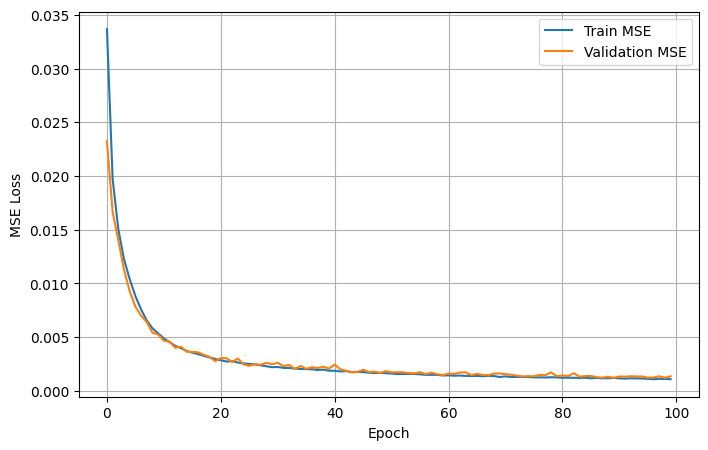

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(rnn_history.history['loss'], label='Train MSE')
plt.plot(rnn_history.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
#plt.title('Training vs Validation MSE Loss')
plt.legend()
plt.grid(True)
plt.show()